In [27]:
import numpy as np
import pandas as pd
import geopandas as gpd
import rasterio as rio
from rasterio.warp import transform_bounds
from matplotlib import pyplot as plt
from cartopy import crs as ccrs
from cartopy.io.img_tiles import Stamen, OSM, GoogleTiles, QuadtreeTiles
import pyproj
import os
from pathlib import Path

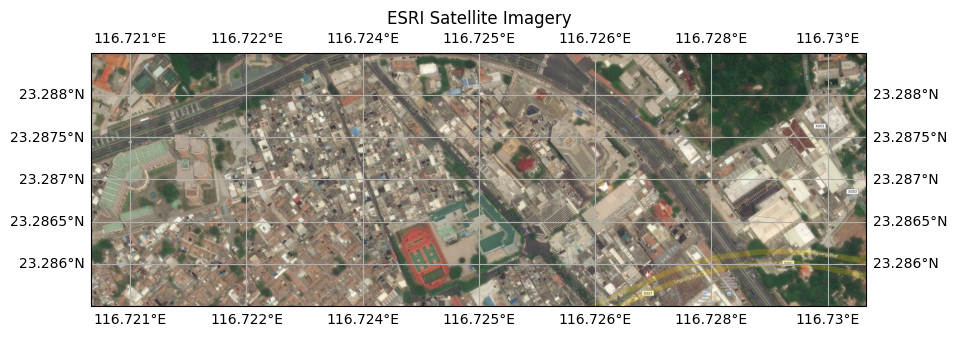

In [2]:
# 1. 创建卫星图层
tiler = QuadtreeTiles()  # ESRI Satellite Imagery
# 可替换为 Stamen('terrain'), Stamen('toner'), OSM(), GoogleTiles(), etc.

# 2. 获取坐标参考系（投影）
mercator = tiler.crs

# 3. 创建图像和设置投影
fig = plt.figure(figsize=(10, 10))
ax = plt.axes(projection=mercator)

# 4. 设置可视区域（经纬度范围）
ax.set_extent([116.72, 116.73, 23.2855, 23.2885], crs=ccrs.PlateCarree())  # 比如中国南部区域

# 5. 添加图层
ax.add_image(tiler, 19)  # 图层等级，数字越大越清晰（zoom level）

# 6. 添加经纬度网格线等可选元素
ax.gridlines(draw_labels=True)

plt.title("ESRI Satellite Imagery")
plt.show()

In [64]:
DEM_ = rio.open(r"D:\wty\Dropbox\code\20250304\results\GMTED2010_EckertIV.tif")
habitats_lv2_ = rio.open(r'../results/terrestrial-habitat-class-maps/habitat-classifications-lv2-1km.tif')

In [78]:
taxon = 'mammals'
a_species = 'Saccopteryx antioquensis'
habitat_preferences = pd.read_csv(os.path.join('..', 'results', 'iucn-assessments', f'habitat-preferences-{taxon}.csv'))
range_index = pd.read_csv(os.path.join('..', 'results', 'species-range-rasters', f'range-index-{taxon}.csv'))
elevation_range = pd.read_csv(os.path.join('..', 'results', 'iucn-assessments', f'elevation-range-{taxon}.csv'))
catalogue = pd.read_csv(os.path.join('..', 'results', 'area-of-habitat', f'catalogue-{taxon}.csv'))
range_map_raster_ = rio.open(os.path.join('..', 'results', 'species-range-rasters', taxon, f'{a_species}.tif'))
# AOH_raster_ = rio.open(os.path.join('..', 'results', 'area-of-habitat', taxon, f'{a_species}.tif'))

range_map_raster = range_map_raster_.read(1)
# AOH_raster = AOH_raster_.read(1)

mercator_bounds = transform_bounds(range_map_raster_.crs, 'EPSG:3857',
                                   range_map_raster_.bounds.left, range_map_raster_.bounds.bottom,
                                   range_map_raster_.bounds.right, range_map_raster_.bounds.top)

latlon_bounds = transform_bounds(range_map_raster_.crs, 'EPSG:4326',
                                 range_map_raster_.bounds.left, range_map_raster_.bounds.bottom,
                                 range_map_raster_.bounds.right, range_map_raster_.bounds.top,
                                 densify_pts=21)  # 增加精度，防止边界变形
                                 
display_extent = [mercator_bounds[0], mercator_bounds[2], mercator_bounds[1], mercator_bounds[3]]


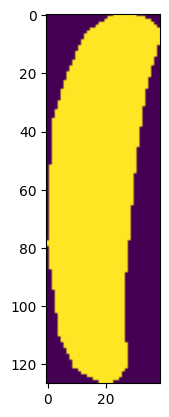

In [81]:
plt.imshow(range_map_raster)

In [91]:
try:
    lower_ele = elevation_range[elevation_range['scientific_name'] == a_species]['lower'].values[0]
except:
    lower_ele = np.nan 

try:
    upper_ele = elevation_range[elevation_range['scientific_name'] == a_species]['upper'].values[0]
except:
    upper_ele = np.nan

print(lower_ele, upper_ele)

all_codes_ = habitat_preferences[habitat_preferences['scientific_name'] == a_species]['code'].values.tolist()
print(all_codes)
all_codes = [int(a.split('_')[0]) * 100 + int(a.split('_')[1]) if '_' in a else int(a) * 100 for a in all_codes_]

y_1 = range_index.loc[range_index['name'] == a_species, 'row_min'].values[0]
y_2 = range_index.loc[range_index['name'] == a_species, 'row_max'].values[0]
x_1 = range_index.loc[range_index['name'] == a_species, 'col_min'].values[0]
x_2 = range_index.loc[range_index['name'] == a_species, 'col_max'].values[0]
a_window = ((y_1, y_2+1), (x_1, x_2+1)) 

local_DEM = DEM_.read(1, window=a_window)
local_habitats = habitats_lv2_.read(1, window=a_window) 

habitat_mask = np.isin(local_habitats, all_codes)

if np.isnan(lower_ele) & ~np.isnan(upper_ele):
    elevation_mask = np.where(local_DEM <= upper_ele, True, False) 
elif ~np.isnan(lower_ele) & np.isnan(upper_ele):
    elevation_mask = np.where(local_DEM >= lower_ele, True, False) 
elif np.isnan(lower_ele) & np.isnan(upper_ele):
    elevation_mask = np.where(~np.isnan(local_DEM), True, False)
else: 
    elevation_mask = np.where((local_DEM >= lower_ele) & (local_DEM <= upper_ele), True, False)

# a_AOH = np.where(habitat_mask & elevation_mask, a_range, 0)


650.0 1200.0
[701, 106]


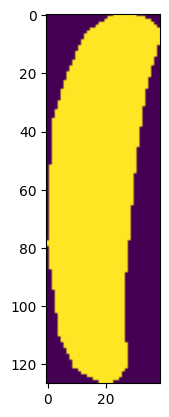

In [83]:
plt.imshow(range_map_raster)

In [86]:
np.max(local_DEM[elevation_mask])

np.float64(1454.4244026998751)

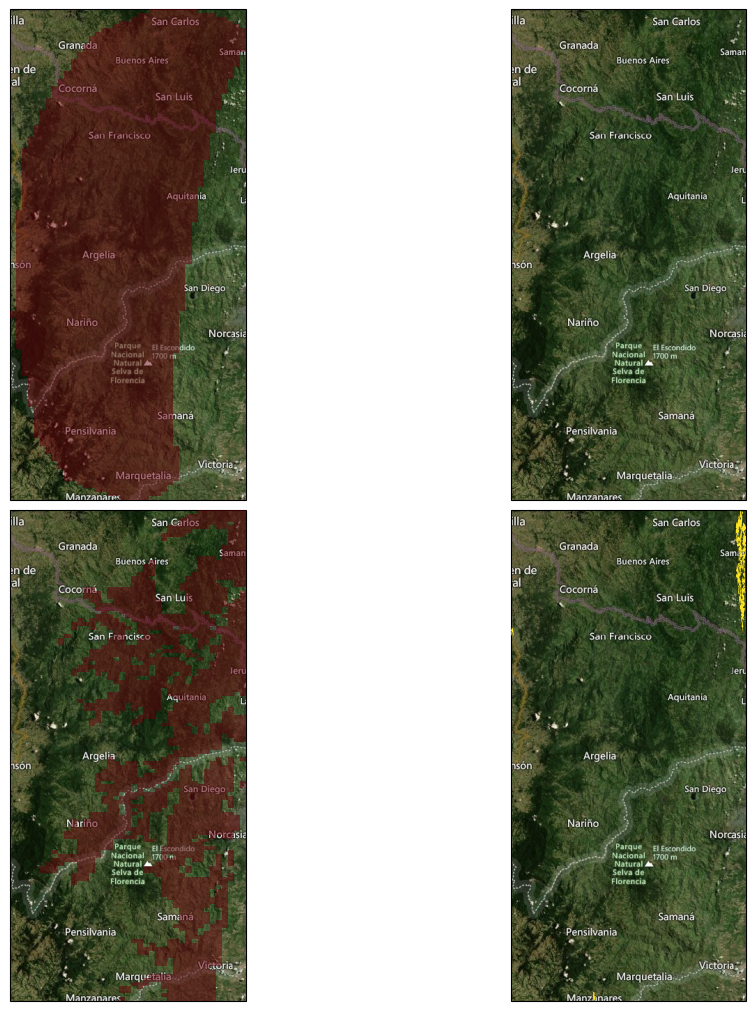

In [90]:
fig = plt.figure(figsize=(10, 10), constrained_layout=True)

ax1 = plt.subplot(221, projection=mercator)
ax1.imshow(np.where(range_map_raster == 1, 1, np.nan), cmap='Reds_r', extent=display_extent, alpha=0.5, zorder=5)
ax1.set_extent([latlon_bounds[0], latlon_bounds[2], latlon_bounds[1], latlon_bounds[3]], crs=ccrs.PlateCarree()) 
ax1.add_image(tiler, 10)

ax2 = plt.subplot(222, projection=mercator)
ax2.imshow(np.where(habitat_mask == True, 1, np.nan), cmap='Reds_r', extent=display_extent, alpha=0.5, zorder=5)
ax2.set_extent([latlon_bounds[0], latlon_bounds[2], latlon_bounds[1], latlon_bounds[3]], crs=ccrs.PlateCarree()) 
ax2.add_image(tiler, 10)

ax3 = plt.subplot(223, projection=mercator)
ax3.imshow(np.where(elevation_mask == True, 1, np.nan), cmap='Reds_r', extent=display_extent, alpha=0.5, zorder=5)
ax3.set_extent([latlon_bounds[0], latlon_bounds[2], latlon_bounds[1], latlon_bounds[3]], crs=ccrs.PlateCarree()) 
ax3.add_image(tiler, 10)


ax2 = plt.subplot(224, projection=mercator)
ax2.imshow(np.where(AOH_raster == 1, 1, np.nan), cmap='viridis_r', extent=display_extent, alpha=1.0, zorder=5)
ax2.set_extent([latlon_bounds[0], latlon_bounds[2], latlon_bounds[1], latlon_bounds[3]], crs=ccrs.PlateCarree()) 
ax2.add_image(tiler, 10)

plt.show()